# Quantum noise floor: $\delta_k(\alpha, \zeta)$

This notebook characterizes the primitive-state leakage probability used in Eq. 23 / Eq. 24 by sweeping coherent amplitude $\alpha$ and squeezing $\zeta$.

The plotted quantity is

$$\delta_k = \langle \Theta_{\alpha,\zeta} | M_k | \Theta_{\alpha,\zeta}\rangle,$$

where $M_k$ is the phase-sector POVM element constructed by `ContinuousProtocol._create_phase_parity_measurement(k)`. By default we use $k=\lceil (d/m_c)/2\rceil$, matching the adjacent-section offset used for the floor $1-F_{\max}=2\delta_k$.

In [1]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from qutip import coherent, displace, squeeze

repo_root = Path.cwd().resolve()
if repo_root.name == "notebook":
    repo_root = repo_root.parent
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from continuous import ContinuousProtocol

## Sweep parameters

Increase `N` if the largest `alpha` or most negative squeezing approaches the Fock cutoff. The quick cutoff check below reports the largest population in the final few Fock levels.

In [17]:
d = 16
m_i = 16
m_c = 8
N = 220

assert d % m_c == 0, "The phase-sector construction assumes d is divisible by m_c."

# Eq. 24 uses k = ceil(Delta_c / 2), where Delta_c = d / m_c.
delta_c = d / m_c
k = int(np.ceil(delta_c / 2))

alpha_values = np.linspace(3.0, 10.0, 15)
squeezing_values = np.linspace(-1.2, 0.0, 15)

print(f"Using k={k}, d={d}, m_c={m_c}, Delta_c={delta_c}, N={N}")

Using k=1, d=16, m_c=8, Delta_c=2.0, N=220


In [18]:
protocol = ContinuousProtocol(coherent(N, 0), res=d, m_i=m_i, m_c=m_c)
phase_sector = protocol._create_phase_parity_measurement(k)


def primitive_state(alpha, zeta, N=N):
    """Primitive state |Theta_{alpha,zeta}> used in the continuous simulations."""
    if np.isclose(zeta, 0.0):
        return coherent(N, alpha)
    return displace(N, alpha) * squeeze(N, zeta) * coherent(N, 0)


def delta_k(alpha, zeta):
    state = primitive_state(alpha, zeta)
    value = state.dag() * phase_sector * state
    return float(np.real_if_close(value.full()[0, 0]))


def cutoff_tail(alpha, zeta, tail_size=10):
    state = primitive_state(alpha, zeta)
    probabilities = np.abs(state.full().ravel()) ** 2
    return float(probabilities[-tail_size:].sum())

## Compute the grid

In [19]:
delta_grid = np.empty((len(squeezing_values), len(alpha_values)))

for row, zeta in enumerate(squeezing_values):
    for col, alpha in enumerate(alpha_values):
        delta_grid[row, col] = delta_k(alpha, zeta)

floor_grid = 2 * delta_grid

tail_checks = {
    "min_alpha_min_squeezing": cutoff_tail(alpha_values.min(), squeezing_values.min()),
    "max_alpha_min_squeezing": cutoff_tail(alpha_values.max(), squeezing_values.min()),
    "max_alpha_zero_squeezing": cutoff_tail(alpha_values.max(), 0.0),
}
tail_checks

{'min_alpha_min_squeezing': 1.95283947523554e-12,
 'max_alpha_min_squeezing': 0.0024379042593250157,
 'max_alpha_zero_squeezing': 6.643755275431682e-22}

## Heatmaps

The logarithmic color scale makes the noise floor visible over several orders of magnitude.

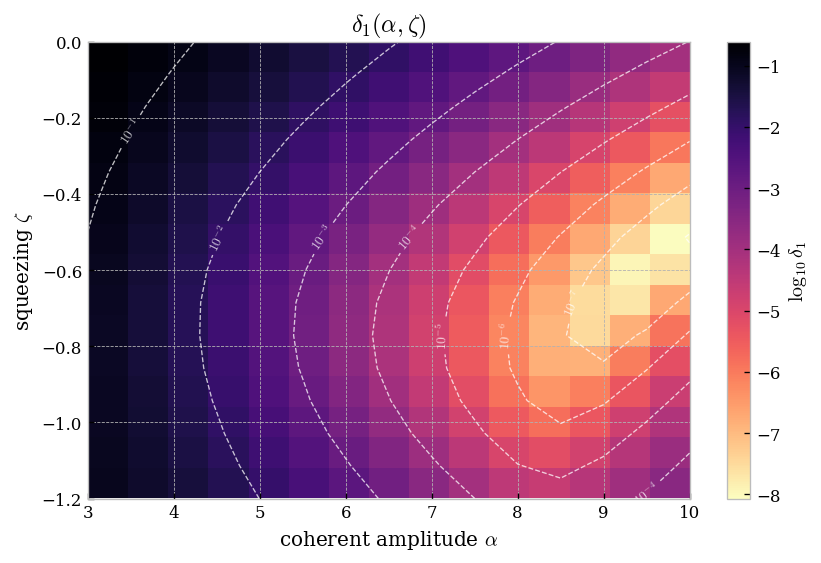

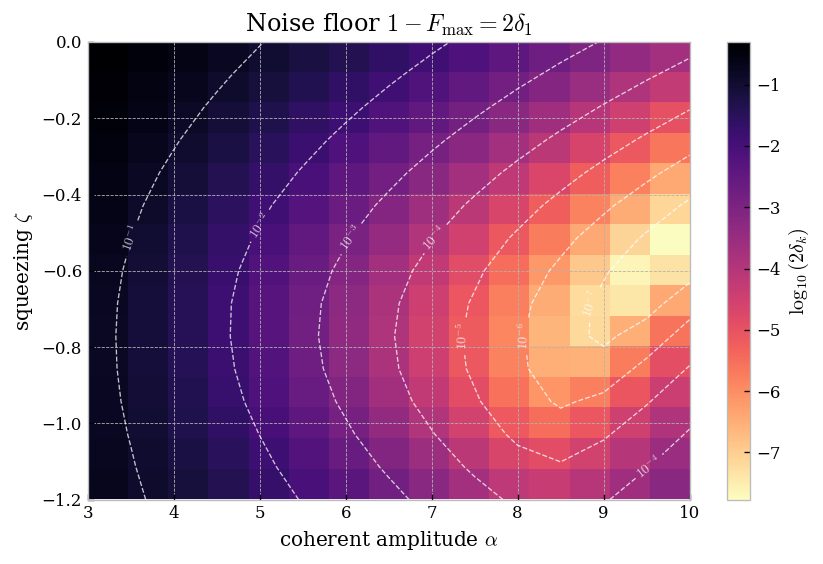

In [20]:
mpl.rcParams["text.usetex"] = False
mpl.rcParams["font.family"] = "DejaVu Serif"
plt.style.use("bmh")


def plot_log_heatmap(values, title, colorbar_label):
    safe_values = np.clip(values, np.finfo(float).tiny, None)
    log_values = np.log10(safe_values)

    fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=120)
    image = ax.imshow(
        log_values,
        origin="lower",
        aspect="auto",
        extent=[alpha_values.min(), alpha_values.max(), squeezing_values.min(), squeezing_values.max()],
        cmap="magma_r",
    )
    contours = ax.contour(
        alpha_values,
        squeezing_values,
        log_values,
        colors="white",
        linewidths=0.8,
        alpha=0.75,
    )
    ax.clabel(contours, inline=True, fontsize=8, fmt=lambda x: f"$10^{{{x:.0f}}}$")
    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_label(colorbar_label)
    ax.set_xlabel(r"coherent amplitude $\alpha$")
    ax.set_ylabel(r"squeezing $\zeta$")
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax


plot_log_heatmap(delta_grid, rf"$\delta_{{{k}}}(\alpha,\zeta)$", rf"$\log_{{10}} \delta_{{{k}}}$");
plot_log_heatmap(floor_grid, rf"Noise floor $1-F_{{\max}}=2\delta_{{{k}}}$", r"$\log_{10}(2\delta_k)$");

## Slices through the grid

These one-dimensional cuts are useful for picking representative parameter values for the paper text.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

for zeta in [0.0, -0.4, -0.8, -1.2]:
    row = np.argmin(np.abs(squeezing_values - zeta))
    axes[0].semilogy(alpha_values, delta_grid[row], ".-", label=rf"$\zeta={squeezing_values[row]:.2f}$")

for alpha in [4.0, 6.0, 8.0, 10.0]:
    col = np.argmin(np.abs(alpha_values - alpha))
    axes[1].semilogy(squeezing_values, delta_grid[:, col], ".-", label=rf"$\alpha={alpha_values[col]:.1f}$")

axes[0].set_xlabel(r"coherent amplitude $\alpha$")
axes[0].set_ylabel(rf"$\delta_{{{k}}}$")
axes[0].set_title("Fixed squeezing")
axes[0].legend()

axes[1].set_xlabel(r"squeezing $\zeta$")
axes[1].set_ylabel(rf"$\delta_{{{k}}}$")
axes[1].set_title("Fixed amplitude")
axes[1].legend()

fig.tight_layout()

## Optional: save data and figures

In [ ]:
output_dir = repo_root / "results" / "delta_grid"
output_dir.mkdir(parents=True, exist_ok=True)
np.savez(
    output_dir / f"delta_grid_d={d}_m_c={m_c}_N={N}.npz",
    alpha_values=alpha_values,
    squeezing_values=squeezing_values,
    delta_grid=delta_grid,
    floor_grid=floor_grid,
    d=d,
    m_i=m_i,
    m_c=m_c,
    N=N,
    k=k,
)
plt.savefig(output_dir / f"delta_grid_d={d}_m_c={m_c}_N={N}.pdf", bbox_inches="tight")